# Daily & Session Range Analyzer

Historical daily and session range analysis for Candle Fetcher.

## Phase 1 ? Historical Range Analysis

Analyse daily highs, lows, point ranges and percentage ranges for Asia, London and New York.

In [2]:
from pathlib import Path
import sys

# Find the Candle Fetcher project root.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.range_analysis import (     calculate_range,     calculate_daily_ranges,     calculate_session_ranges,     calculate_session_ranges_with_quality, )

print('SUCCESS: Range Analyzer imports loaded!')

SUCCESS: Range Analyzer imports loaded!


In [3]:
# Step 2 ? Load historical candle data

DATA_FOLDER = PROJECT_ROOT / "data" / "processed" / "all_sessions"

available_files = sorted(DATA_FOLDER.glob("*.csv"))

print("Available historical datasets:")
for index, file in enumerate(available_files, start=1):
    print(f"{index}. {file.name}")

# Choose the dataset to analyse.
CSV_FILENAME = "2025_full_year.csv"

csv_path = DATA_FOLDER / CSV_FILENAME

if not csv_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {csv_path}")

df = pd.read_csv(csv_path, parse_dates=["datetime"])

print(f"\nLoaded: {CSV_FILENAME}")
print(f"Candles: {len(df):,}")
print(f"First candle: {df['datetime'].min()}")
print(f"Last candle: {df['datetime'].max()}")

display(df.head())


Available historical datasets:
1. 2023_full_year.csv
2. 2024_full_year.csv
3. 2025_full_year.csv
4. us100_cash_M1_all_sessions_2024_01_01_to_2024_12_31.csv
5. us100_cash_M1_all_sessions_2024_01_01_to_2025_01_01.csv

Loaded: 2025_full_year.csv
Candles: 348,793
First candle: 2025-01-02 01:05:00+00:00
Last candle: 2025-12-31 23:49:00+00:00


,datetime,open,high,low,close,tick_volume,spread,real_volume,session_name
0,2025-01-02 01:05:00+00:00,21100.15,21104.25,21088.65,21093.65,153,290,0,all_sessions
1,2025-01-02 01:06:00+00:00,21093.15,21093.75,21086.05,21091.35,119,290,0,all_sessions
2,2025-01-02 01:07:00+00:00,21091.65,21092.05,21086.15,21088.25,73,290,0,all_sessions
3,2025-01-02 01:08:00+00:00,21088.85,21097.25,21087.25,21096.05,70,290,0,all_sessions
4,2025-01-02 01:09:00+00:00,21098.05,21099.25,21091.75,21092.15,85,290,0,all_sessions


In [4]:
# Step 2.5 — New York session ranges with data quality

ny_quality = calculate_session_ranges_with_quality(
    df,
    session_name="new_york",
)

print("NEW YORK — HISTORICAL RANGE & QUALITY ANALYSIS")
print("-" * 50)

print(f"Sessions analysed: {len(ny_quality)}")
print(f"Complete sessions: {int(ny_quality['is_complete'].sum())}")
print(f"Incomplete sessions: {int((~ny_quality['is_complete']).sum())}")

display(
    ny_quality[
        [
            "trading_date",
            "range_points",
            "candle_count",
            "missing_candles",
            "duplicate_candles",
            "is_complete",
        ]
    ].head(10)
)

NEW YORK — HISTORICAL RANGE & QUALITY ANALYSIS
--------------------------------------------------
Sessions analysed: 258
Complete sessions: 254
Incomplete sessions: 4


,trading_date,range_points,candle_count,missing_candles,duplicate_candles,is_complete
0,2025-01-02,322.1,200,0,0,True
1,2025-01-03,230.5,200,0,0,True
2,2025-01-06,242.5,200,0,0,True
3,2025-01-07,279.6,200,0,0,True
4,2025-01-08,184.6,200,0,0,True
5,2025-01-09,69.0,140,60,0,False
6,2025-01-10,445.8,200,0,0,True
7,2025-01-13,152.1,200,0,0,True
8,2025-01-14,193.6,200,0,0,True
9,2025-01-15,429.1,200,0,0,True


In [5]:
# Step 2.6 — London session ranges with data quality

london_quality = calculate_session_ranges_with_quality(
    df,
    session_name="london",
)

print("LONDON — HISTORICAL RANGE & QUALITY ANALYSIS")
print("-" * 50)

print(f"Sessions analysed: {len(london_quality)}")
print(f"Complete sessions: {int(london_quality['is_complete'].sum())}")
print(f"Incomplete sessions: {int((~london_quality['is_complete']).sum())}")

display(
    london_quality[
        [
            "trading_date",
            "range_points",
            "candle_count",
            "missing_candles",
            "duplicate_candles",
            "is_complete",
        ]
    ].head(10)
)

LONDON — HISTORICAL RANGE & QUALITY ANALYSIS
--------------------------------------------------
Sessions analysed: 258
Complete sessions: 257
Incomplete sessions: 1


,trading_date,range_points,candle_count,missing_candles,duplicate_candles,is_complete
0,2025-01-02,105.5,180,0,0,True
1,2025-01-03,64.0,180,0,0,True
2,2025-01-06,93.9,180,0,0,True
3,2025-01-07,81.2,180,0,0,True
4,2025-01-08,73.9,180,0,0,True
5,2025-01-09,110.6,180,0,0,True
6,2025-01-10,67.3,180,0,0,True
7,2025-01-13,131.3,180,0,0,True
8,2025-01-14,121.9,180,0,0,True
9,2025-01-15,50.1,180,0,0,True


In [6]:
# Step 2.7 — Asia session ranges with data quality

asia_quality = calculate_session_ranges_with_quality(
    df,
    session_name="asia",
    reference_start="10:05",
)

print("ASIA — HISTORICAL RANGE & QUALITY ANALYSIS")
print("-" * 50)

print(f"Sessions analysed: {len(asia_quality)}")
print(f"Complete sessions: {int(asia_quality['is_complete'].sum())}")
print(f"Incomplete sessions: {int((~asia_quality['is_complete']).sum())}")

display(
    asia_quality[
        [
            "trading_date",
            "range_points",
            "candle_count",
            "missing_candles",
            "duplicate_candles",
            "is_complete",
        ]
    ].head(10)
)

ASIA — HISTORICAL RANGE & QUALITY ANALYSIS
--------------------------------------------------
Sessions analysed: 258
Complete sessions: 257
Incomplete sessions: 1


,trading_date,range_points,candle_count,missing_candles,duplicate_candles,is_complete
0,2025-01-02,198.6,115,0,0,True
1,2025-01-03,95.1,115,0,0,True
2,2025-01-06,58.2,115,0,0,True
3,2025-01-07,40.7,115,0,0,True
4,2025-01-08,69.5,115,0,0,True
5,2025-01-09,75.3,115,0,0,True
6,2025-01-10,117.3,115,0,0,True
7,2025-01-13,93.4,115,0,0,True
8,2025-01-14,67.5,115,0,0,True
9,2025-01-15,24.4,115,0,0,True


In [7]:
# Step 2.8 — Identify incomplete trading sessions

all_quality = pd.concat(
    [asia_quality, london_quality, ny_quality],
    ignore_index=True,
)

incomplete_sessions = all_quality.loc[
    ~all_quality["is_complete"]
].copy()

print("INCOMPLETE TRADING SESSIONS — 2025")
print("-" * 50)
print(f"Total incomplete sessions: {len(incomplete_sessions)}")

display(
    incomplete_sessions[
        [
            "trading_date",
            "session",
            "candle_count",
            "expected_candles",
            "missing_candles",
            "duplicate_candles",
            "range_points",
        ]
    ].sort_values(["trading_date", "session"])
)

INCOMPLETE TRADING SESSIONS — 2025
--------------------------------------------------
Total incomplete sessions: 6


,trading_date,session,candle_count,expected_candles,missing_candles,duplicate_candles,range_points
521,2025-01-09,new_york,140,200,60,0,69.00
40,2025-02-27,asia,114,115,1,0,129.22
564,2025-03-11,new_york,196,200,4,0,168.50
493,2025-11-28,london,2,180,178,0,1.50
751,2025-11-28,new_york,100,200,100,0,89.50
762,2025-12-15,new_york,181,200,19,0,373.20


In [8]:
# Step 2.9 — Compare raw and quality-filtered session ranges

summary_rows = []

for name, session_data in [
    ("Asia", asia_quality),
    ("London", london_quality),
    ("New York", ny_quality),
]:
    complete_data = session_data.loc[
        session_data["is_complete"]
    ]

    summary_rows.append({
        "session": name,
        "total_sessions": len(session_data),
        "complete_sessions": len(complete_data),
        "raw_mean_range": round(
            session_data["range_points"].mean(), 2
        ),
        "filtered_mean_range": round(
            complete_data["range_points"].mean(), 2
        ),
        "raw_median_range": round(
            session_data["range_points"].median(), 2
        ),
        "filtered_median_range": round(
            complete_data["range_points"].median(), 2
        ),
    })

quality_summary = pd.DataFrame(summary_rows)

print("RAW VS QUALITY-FILTERED SESSION RANGES — 2025")
display(quality_summary)

RAW VS QUALITY-FILTERED SESSION RANGES — 2025


,session,total_sessions,complete_sessions,raw_mean_range,filtered_mean_range,raw_median_range,filtered_median_range
0,Asia,258,257,74.24,74.03,60.8,60.69
1,London,258,257,80.22,80.53,67.1,67.30
2,New York,258,254,161.81,161.60,127.3,127.30


In [9]:
# Step 2.10 — Complete-session range percentiles

percentile_rows = []

for name, session_data in [
    ("Asia", asia_quality),
    ("London", london_quality),
    ("New York", ny_quality),
]:
    complete = session_data.loc[
        session_data["is_complete"], "range_points"
    ]

    percentile_rows.append({
        "session": name,
        "complete_sessions": len(complete),
        "P10": round(complete.quantile(0.10), 2),
        "P25": round(complete.quantile(0.25), 2),
        "P50": round(complete.quantile(0.50), 2),
        "P75": round(complete.quantile(0.75), 2),
        "P90": round(complete.quantile(0.90), 2),
    })

percentile_summary = pd.DataFrame(percentile_rows)

print("COMPLETE-SESSION RANGE PERCENTILES — 2025")
display(percentile_summary)

COMPLETE-SESSION RANGE PERCENTILES — 2025


,session,complete_sessions,P10,P25,P50,P75,P90
0,Asia,257,27.40,36.39,60.69,89.49,134.09
1,London,257,36.66,47.10,67.30,97.30,132.54
2,New York,254,54.64,77.93,127.30,218.02,324.76


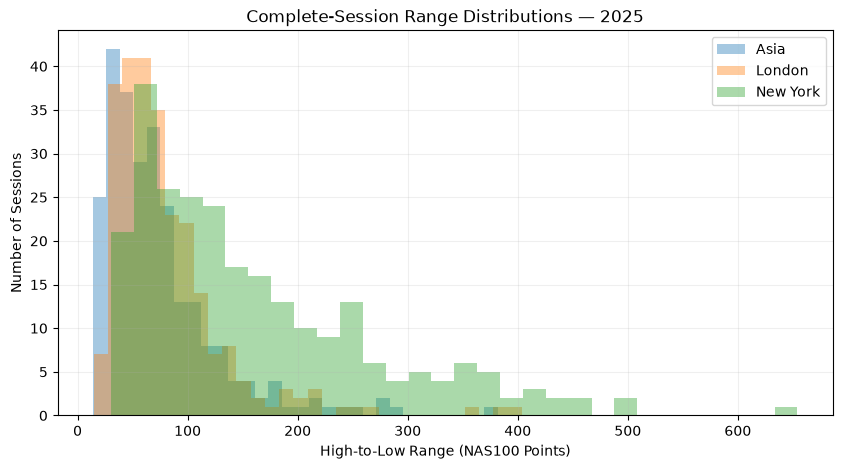

In [10]:
# Step 2.11 — Compare complete-session range distributions

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

for name, session_data in [
    ("Asia", asia_quality),
    ("London", london_quality),
    ("New York", ny_quality),
]:
    complete_ranges = session_data.loc[
        session_data["is_complete"], "range_points"
    ]

    ax.hist(
        complete_ranges,
        bins=30,
        alpha=0.4,
        label=name,
    )

ax.set_title("Complete-Session Range Distributions — 2025")
ax.set_xlabel("High-to-Low Range (NAS100 Points)")
ax.set_ylabel("Number of Sessions")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

In [ ]:

# Step 3 — Calculate historical daily ranges

daily_ranges = calculate_daily_ranges(
    df,
    timezone="UTC"
)

print("DAILY RANGE ANALYSIS — 2025")
print(f"Trading dates found: {len(daily_ranges)}")

display(daily_ranges.head(10))


In [ ]:
# Step 4 — Inspect historical daily candle coverage

coverage = (
    daily_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_day")
    .reset_index(name="number_of_days")
)

print("DAILY CANDLE COVERAGE — 2025")
display(coverage)

In [ ]:
# Step 5 — Identify dates with reduced candle coverage

EXPECTED_CANDLES = 1365

reduced_coverage = daily_ranges[
    daily_ranges["candle_count"] < EXPECTED_CANDLES
].copy()

reduced_coverage["missing_vs_reference"] = (
    EXPECTED_CANDLES - reduced_coverage["candle_count"]
)

print("DATES WITH REDUCED CANDLE COVERAGE — 2025")
print(f"Number of dates: {len(reduced_coverage)}")

display(
    reduced_coverage[
        [
            "trading_date",
            "candle_count",
            "missing_vs_reference",
            "range_points",
            "range_percent"
        ]
    ]
)

In [ ]:
# Step 6 — Classify daily candle coverage

EXPECTED_CANDLES = 1365

daily_ranges["coverage_status"] = daily_ranges[
    "candle_count"
].apply(
    lambda count: (
        "reference_coverage"
        if count == EXPECTED_CANDLES
        else "reduced_coverage"
    )
)

print("DAILY COVERAGE CLASSIFICATION — 2025")

coverage_summary = (
    daily_ranges["coverage_status"]
    .value_counts()
    .rename_axis("coverage_status")
    .reset_index(name="number_of_days")
)

display(coverage_summary)

In [ ]:

# Step 7 — Historical daily range statistics

reference_days = daily_ranges[
    daily_ranges["coverage_status"] == "reference_coverage"
].copy()

ranges = reference_days["range_points"]

daily_statistics = pd.DataFrame({
    "Metric": [
        "Trading days",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(ranges),
        ranges.mean(),
        ranges.median(),
        ranges.min(),
        ranges.max(),
        ranges.quantile(0.10),
        ranges.quantile(0.25),
        ranges.quantile(0.75),
        ranges.quantile(0.90)
    ]
})

daily_statistics["Value"] = daily_statistics["Value"].round(2)

print("NAS100 — HISTORICAL DAILY RANGE STATISTICS (2025)")
print("Reference-coverage days only")

display(daily_statistics)


In [ ]:
# Step 8 — Investigate the largest historical daily ranges

largest_days = (
    reference_days
    .sort_values("range_points", ascending=False)
    .head(10)
)

print("TOP 10 LARGEST DAILY RANGES — 2025")

display(
    largest_days[
        [
            "trading_date",
            "high",
            "low",
            "range_points",
            "range_percent",
            "candle_count"
        ]
    ]
)

In [ ]:

# Step 9 — Inspect the largest daily range

selected_date = "2025-04-09"

day_candles = df[
    df["datetime"].dt.strftime("%Y-%m-%d") == selected_date
].copy()

highest_candle = day_candles.loc[
    day_candles["high"].idxmax()
]

lowest_candle = day_candles.loc[
    day_candles["low"].idxmin()
]

print(f"DAILY RANGE INVESTIGATION — {selected_date}")
print(f"Total candles: {len(day_candles):,}")

print("\nDAILY HIGH")
print(f"Time (UTC): {highest_candle['datetime']}")
print(f"Price: {highest_candle['high']:,.2f}")

print("\nDAILY LOW")
print(f"Time (UTC): {lowest_candle['datetime']}")
print(f"Price: {lowest_candle['low']:,.2f}")

print("\nTOTAL RANGE")
print(
    f"{highest_candle['high'] - lowest_candle['low']:,.2f} points"
)


In [ ]:

# Step 10 — Calculate historical New York session ranges

ny_ranges = calculate_session_ranges(
    df,
    session_name="new_york"
)

print("NEW YORK SESSION RANGES — 2025")
print(f"Trading dates found: {len(ny_ranges)}")

display(ny_ranges.head(10))


In [ ]:
# Step 11 — Check New York session candle coverage

ny_coverage = (
    ny_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

print("NEW YORK SESSION COVERAGE — 2025")
display(ny_coverage)

print(f"\nTotal sessions: {len(ny_ranges)}")
print(
    "Sessions with exactly 200 candles:",
    (ny_ranges["candle_count"] == 200).sum()
)

In [ ]:

# Step 12 — New York historical session range statistics

ny_reference = ny_ranges[
    ny_ranges["candle_count"] == 200
].copy()

ny_points = ny_reference["range_points"]

ny_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(ny_points),
        ny_points.mean(),
        ny_points.median(),
        ny_points.min(),
        ny_points.max(),
        ny_points.quantile(0.10),
        ny_points.quantile(0.25),
        ny_points.quantile(0.75),
        ny_points.quantile(0.90)
    ]
})

ny_statistics["Value"] = ny_statistics["Value"].round(2)

print("NAS100 — NEW YORK SESSION RANGE STATISTICS (2025)")
print("Session: 09:10–12:30 America/New_York")
print("Sessions with 200 candles only")

display(ny_statistics)


In [ ]:

# Step 13 — Calculate historical London session ranges

london_ranges = calculate_session_ranges(
    df,
    session_name="london"
)

print("LONDON SESSION RANGES — 2025")
print("Session: 08:00–11:00 Europe/London")
print(f"Trading dates found: {len(london_ranges)}")

display(london_ranges.head(10))

print("\nLONDON SESSION CANDLE COVERAGE")

london_coverage = (
    london_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

display(london_coverage)



In [ ]:

# Step 14 — London historical session range statistics

london_reference = london_ranges[
    london_ranges["candle_count"] == 180
].copy()

london_points = london_reference["range_points"]

london_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(london_points),
        london_points.mean(),
        london_points.median(),
        london_points.min(),
        london_points.max(),
        london_points.quantile(0.10),
        london_points.quantile(0.25),
        london_points.quantile(0.75),
        london_points.quantile(0.90)
    ]
})

london_statistics["Value"] = london_statistics["Value"].round(2)

print("NAS100 — LONDON SESSION RANGE STATISTICS (2025)")
print("Session: 08:00–11:00 Europe/London")
print("Sessions with 180 candles only")

display(london_statistics)


In [ ]:

# Step 15 — Calculate historical Asia session ranges

asia_ranges = calculate_session_ranges(
    df,
    session_name="asia"
)

print("ASIA SESSION RANGES — 2025")
print("Session: 09:00–12:00 Asia/Tokyo")
print(f"Trading dates found: {len(asia_ranges)}")

display(asia_ranges.head(10))

print("\nASIA SESSION CANDLE COVERAGE")

asia_coverage = (
    asia_ranges["candle_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candles_per_session")
    .reset_index(name="number_of_sessions")
)

display(asia_coverage)


In [ ]:

# Step 16 — Inspect Asia session candle timestamps

selected_date = "2025-01-02"

asia_candles = df[
    df["datetime"].dt.tz_convert("Asia/Tokyo")
    .dt.strftime("%Y-%m-%d") == selected_date
].copy()

asia_local = asia_candles[
    "datetime"
].dt.tz_convert("Asia/Tokyo")

asia_candles = asia_candles[
    (asia_local.dt.hour >= 9) &
    (asia_local.dt.hour < 12)
].copy()

print(f"ASIA SESSION TIMESTAMP CHECK — {selected_date}")
print(f"Total candles: {len(asia_candles)}")

print("\nFirst 10 timestamps:")
print(
    asia_candles["datetime"]
    .dt.tz_convert("Asia/Tokyo")
    .head(10)
    .to_string(index=False)
)

print("\nLast 10 timestamps:")
print(
    asia_candles["datetime"]
    .dt.tz_convert("Asia/Tokyo")
    .tail(10)
    .to_string(index=False)
)

print("\nGaps larger than one minute:")

time_gaps = asia_candles[
    "datetime"
].diff()

print(time_gaps[time_gaps > pd.Timedelta(minutes=1)])


In [ ]:

# Step 17 — Asia historical session range statistics

asia_reference = asia_ranges[
    asia_ranges["candle_count"] == 115
].copy()

asia_points = asia_reference["range_points"]

asia_statistics = pd.DataFrame({
    "Metric": [
        "Sessions analysed",
        "Mean range",
        "Median range (P50)",
        "Minimum range",
        "Maximum range",
        "P10",
        "P25",
        "P75",
        "P90"
    ],
    "Value": [
        len(asia_points),
        asia_points.mean(),
        asia_points.median(),
        asia_points.min(),
        asia_points.max(),
        asia_points.quantile(0.10),
        asia_points.quantile(0.25),
        asia_points.quantile(0.75),
        asia_points.quantile(0.90)
    ]
})

asia_statistics["Value"] = asia_statistics["Value"].round(2)

print("NAS100 — ASIA SESSION RANGE STATISTICS (2025)")
print("Configured: 09:00–12:00 Asia/Tokyo")
print("Observed reference coverage: 10:05–12:00")
print("Sessions with 115 candles only")

display(asia_statistics)


In [ ]:

# Step 18 — Compare daily and session range statistics

datasets = {
    "Full Day": reference_days["range_points"],
    "Asia": asia_reference["range_points"],
    "London": london_reference["range_points"],
    "New York": ny_reference["range_points"],
}

comparison_rows = []

for name, ranges in datasets.items():
    comparison_rows.append({
        "Period": name,
        "Observations": len(ranges),
        "Mean": ranges.mean(),
        "Median": ranges.median(),
        "P10": ranges.quantile(0.10),
        "P25": ranges.quantile(0.25),
        "P75": ranges.quantile(0.75),
        "P90": ranges.quantile(0.90),
        "Maximum": ranges.max(),
    })

range_comparison = pd.DataFrame(comparison_rows)

numeric_columns = range_comparison.select_dtypes(
    include="number"
).columns.drop("Observations")

range_comparison[numeric_columns] = (
    range_comparison[numeric_columns].round(2)
)

print("NAS100 — HISTORICAL RANGE COMPARISON (2025)")
print("All ranges measured in index points")

display(range_comparison)


In [ ]:

# Step 19 — Visualise historical daily ranges

import matplotlib.pyplot as plt

chart_data = daily_ranges.copy()
chart_data["trading_date"] = pd.to_datetime(
    chart_data["trading_date"]
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    chart_data["trading_date"],
    chart_data["range_points"],
    linewidth=1.2,
    label="Daily Range"
)

ax.axhline(
    y=reference_days["range_points"].median(),
    linestyle="--",
    linewidth=1.5,
    label="2025 Median Range"
)

ax.set_title("NAS100 — Historical Daily Ranges (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Daily Range (Points)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [ ]:

# Step 20 — Visualise historical session range percentiles

sessions = {
    "Asia": asia_reference["range_points"],
    "London": london_reference["range_points"],
    "New York": ny_reference["range_points"],
}

chart_rows = []

for session_name, ranges in sessions.items():
    chart_rows.append({
        "Session": session_name,
        "Median (P50)": ranges.quantile(0.50),
        "P75": ranges.quantile(0.75),
        "P90": ranges.quantile(0.90),
    })

session_chart_data = pd.DataFrame(chart_rows)
session_chart_data = session_chart_data.set_index("Session")

ax = session_chart_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("NAS100 — Session Range Percentiles (2025)")
ax.set_xlabel("Trading Session")
ax.set_ylabel("Historical Range (Points)")
ax.tick_params(axis="x", rotation=0)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [ ]:

# Step 21 — Historical session ranges over time

fig, ax = plt.subplots(figsize=(14, 6))

session_data = {
    "Asia": asia_ranges,
    "London": london_ranges,
    "New York": ny_ranges,
}

for session_name, session_df in session_data.items():
    dates = pd.to_datetime(session_df["trading_date"])

    ax.plot(
        dates,
        session_df["range_points"],
        linewidth=1.2,
        alpha=0.8,
        label=session_name
    )

ax.set_title("NAS100 — Historical Session Ranges (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Session Range (Points)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [ ]:

# Step 22 — New York rolling average range

ny_chart = ny_ranges.copy()

ny_chart["trading_date"] = pd.to_datetime(
    ny_chart["trading_date"]
)

ny_chart = ny_chart.sort_values("trading_date")

ny_chart["rolling_20"] = (
    ny_chart["range_points"]
    .rolling(window=20, min_periods=20)
    .mean()
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    ny_chart["trading_date"],
    ny_chart["range_points"],
    alpha=0.35,
    linewidth=1,
    label="Daily NY Session Range"
)

ax.plot(
    ny_chart["trading_date"],
    ny_chart["rolling_20"],
    linewidth=2.5,
    label="20-Session Rolling Average"
)

ax.set_title("NAS100 — New York Session Range Trend (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Range (Points)")

ax.legend()
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [ ]:

# Step 23 — Compare 20-session rolling average ranges

rolling_sessions = {
    "Asia": asia_ranges,
    "London": london_ranges,
    "New York": ny_ranges,
}

fig, ax = plt.subplots(figsize=(14, 6))

for session_name, session_df in rolling_sessions.items():
    session_chart = session_df.copy()

    session_chart["trading_date"] = pd.to_datetime(
        session_chart["trading_date"]
    )

    session_chart = session_chart.sort_values("trading_date")

    session_chart["rolling_20"] = (
        session_chart["range_points"]
        .rolling(window=20, min_periods=20)
        .mean()
    )

    ax.plot(
        session_chart["trading_date"],
        session_chart["rolling_20"],
        linewidth=2,
        label=session_name
    )

ax.set_title("NAS100 — 20-Session Average Range Comparison (2025)")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Average Range (Points)")

ax.legend()
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [ ]:

# Step 24 — Check for duplicate candle timestamps

duplicate_mask = df["datetime"].duplicated(keep=False)

duplicate_candles = df[duplicate_mask].copy()

print("NAS100 — HISTORICAL DATA QUALITY CHECK")
print(f"Total candles: {len(df):,}")
print(f"Duplicate timestamp rows: {len(duplicate_candles):,}")
print(f"Unique timestamps: {df['datetime'].nunique():,}")

if duplicate_candles.empty:
    print("\nSUCCESS: No duplicate candle timestamps found!")
else:
    print("\nWARNING: Duplicate timestamps detected.")
    display(
        duplicate_candles
        .sort_values("datetime")
        .head(20)
    )


In [ ]:

# Step 25 — Identify gaps between candle timestamps

gap_data = df[["datetime"]].copy()

gap_data = gap_data.sort_values("datetime").reset_index(drop=True)

gap_data["previous_candle"] = gap_data["datetime"].shift(1)

gap_data["time_difference"] = (
    gap_data["datetime"] - gap_data["previous_candle"]
)

# Find intervals longer than one minute
gaps = gap_data[
    gap_data["time_difference"] > pd.Timedelta(minutes=1)
].copy()

gaps["gap_minutes"] = (
    gaps["time_difference"].dt.total_seconds() / 60
)

gaps["missing_intervals"] = gaps["gap_minutes"] - 1

print("NAS100 — HISTORICAL CANDLE GAP ANALYSIS (2025)")
print(f"Total candles: {len(df):,}")
print(f"Gaps longer than 1 minute: {len(gaps):,}")

print("\nLargest 15 timestamp gaps:")

display(
    gaps[
        [
            "previous_candle",
            "datetime",
            "gap_minutes",
            "missing_intervals"
        ]
    ]
    .sort_values("gap_minutes", ascending=False)
    .head(15)
)


In [ ]:

# Step 26 — Investigate intraday timestamp gaps

intraday_gaps = gaps[
    gaps["gap_minutes"] < 1440
].copy()

print("NAS100 — INTRADAY GAP ANALYSIS (2025)")

print(f"Total timestamp gaps: {len(gaps)}")
print(f"Gaps shorter than 24 hours: {len(intraday_gaps)}")

print("\nGap duration distribution:")

gap_distribution = (
    intraday_gaps["gap_minutes"]
    .value_counts()
    .sort_index()
    .rename_axis("gap_minutes")
    .reset_index(name="occurrences")
)

display(gap_distribution)

print("\nLargest 10 gaps shorter than 24 hours:")

display(
    intraday_gaps[
        ["previous_candle", "datetime", "gap_minutes"]
    ]
    .sort_values("gap_minutes", ascending=False)
    .head(10)
)


In [ ]:

# Step 27 — Investigate recurring 76-minute gaps

regular_gaps = gaps[
    gaps["gap_minutes"] == 76
].copy()

regular_gaps["previous_time_utc"] = (
    regular_gaps["previous_candle"].dt.strftime("%H:%M")
)

regular_gaps["next_time_utc"] = (
    regular_gaps["datetime"].dt.strftime("%H:%M")
)

print("NAS100 — RECURRING 76-MINUTE GAP ANALYSIS")

print(f"Number of occurrences: {len(regular_gaps)}")

print("\nGap start-time distribution (UTC):")
display(
    regular_gaps["previous_time_utc"]
    .value_counts()
    .rename_axis("previous_candle_time")
    .reset_index(name="occurrences")
)

print("\nGap end-time distribution (UTC):")
display(
    regular_gaps["next_time_utc"]
    .value_counts()
    .rename_axis("next_candle_time")
    .reset_index(name="occurrences")
)


In [ ]:
# Step 28 — Inspect short, nonstandard timestamp gaps

short_gaps = gaps[
    (gaps["gap_minutes"] > 1) &
    (gaps["gap_minutes"] < 76)
].copy()

print("NAS100 — SHORT TIMESTAMP GAP ANALYSIS (2025)")
print(f"Short gaps found: {len(short_gaps)}")

display(
    short_gaps[
        [
            "previous_candle",
            "datetime",
            "gap_minutes",
            "missing_intervals"
        ]
    ].sort_values("previous_candle")
)

In [ ]:

# Step 29 — Inspect short gaps outside Thanksgiving Friday

regular_day_gaps = short_gaps[
    short_gaps["previous_candle"].dt.date
    != pd.Timestamp("2025-11-28").date()
].copy()

print("NAS100 — NON-HOLIDAY SHORT GAP INVESTIGATION")

print(f"Short gaps outside 28 November: {len(regular_day_gaps)}")

display(
    regular_day_gaps[
        [
            "previous_candle",
            "datetime",
            "gap_minutes",
            "missing_intervals"
        ]
    ].sort_values("previous_candle")
)


In [ ]:

# Step 30 — Validate historical candle timestamp ordering

print("NAS100 — TIMESTAMP ORDER VALIDATION")

timestamps = df["datetime"]

is_sorted = timestamps.is_monotonic_increasing

backward_moves = (
    timestamps.diff() < pd.Timedelta(0)
).sum()

print(f"Timestamps correctly ordered: {is_sorted}")
print(f"Backward timestamp movements: {backward_moves}")

if is_sorted and backward_moves == 0:
    print("\nSUCCESS: Candle timestamps are chronologically ordered!")
else:
    print("\nWARNING: Timestamp ordering requires investigation.")


In [ ]:

# Step 31 — Consolidated historical data-quality report

from src.data_quality import (
    validate_timestamps,
    detect_candle_gaps,
    classify_candle_gaps,
)

# Validate the full dataset.
timestamp_report = validate_timestamps(df)

# Detect gaps and classify their patterns.
detected_gaps = detect_candle_gaps(df)
classified_gaps = classify_candle_gaps(detected_gaps)

print("NAS100 — HISTORICAL DATA QUALITY REPORT")
print("=" * 45)

print("\nTIMESTAMP VALIDATION")
for key, value in timestamp_report.items():
    print(f"{key}: {value}")

print("\nGAP CLASSIFICATION")
display(
    classified_gaps["gap_classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="occurrences")
)

print("\nTOTAL GAPS:", len(classified_gaps))


In [ ]:

# Step 32 — Map gaps requiring review to trading dates

review_gaps = classified_gaps[
    classified_gaps["gap_classification"].isin([
        "short_gap_review",
        "extended_gap_review"
    ])
].copy()

# Use the UTC date of the candle before each gap.
review_gaps["trading_date"] = (
    review_gaps["previous_candle"].dt.date
)

daily_gap_summary = (
    review_gaps
    .groupby("trading_date")
    .agg(
        flagged_gaps=("gap_classification", "size"),
        total_gap_minutes=("gap_minutes", "sum")
    )
    .reset_index()
)

print("NAS100 — DATES WITH GAPS REQUIRING REVIEW")
print(f"Dates flagged: {len(daily_gap_summary)}")

display(daily_gap_summary.head(20))


In [ ]:

# Step 33 — Identify Friday-to-Monday weekend gaps

gap_review = classified_gaps.copy()

previous = gap_review["previous_candle"]
current = gap_review["datetime"]

weekend_pattern = (
    (previous.dt.dayofweek == 4)
    & (current.dt.dayofweek == 0)
    & (current.dt.normalize() - previous.dt.normalize()
       == pd.Timedelta(days=3))
)

gap_review["is_weekend_pattern"] = weekend_pattern

print("NAS100 — WEEKEND GAP INVESTIGATION")

print(
    "Friday-to-Monday gaps:",
    int(gap_review["is_weekend_pattern"].sum())
)

print(
    "Other gaps:",
    int((~gap_review["is_weekend_pattern"]).sum())
)

display(
    gap_review.loc[
        gap_review["is_weekend_pattern"],
        ["previous_candle", "datetime", "gap_minutes"]
    ].head(10)
)


In [ ]:

# Step 34 — Investigate non-weekend gap classifications

non_weekend_gaps = gap_review[
    ~gap_review["is_weekend_pattern"]
].copy()

summary = (
    non_weekend_gaps["gap_classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="occurrences")
)

print("NAS100 — NON-WEEKEND GAP CLASSIFICATIONS")
print(f"Total non-weekend gaps: {len(non_weekend_gaps)}")

display(summary)

print("\nEXTENDED GAPS NOT MATCHING FRIDAY-TO-MONDAY")

display(
    non_weekend_gaps[
        non_weekend_gaps["gap_classification"]
        == "extended_gap_review"
    ][
        ["previous_candle", "datetime", "gap_minutes"]
    ].sort_values("previous_candle")
)


In [ ]:

# Step 35 — Examine non-weekend extended gaps

extended_review = non_weekend_gaps[
    non_weekend_gaps["gap_classification"]
    == "extended_gap_review"
].copy()

extended_review["previous_weekday"] = (
    extended_review["previous_candle"].dt.day_name()
)

extended_review["next_weekday"] = (
    extended_review["datetime"].dt.day_name()
)

extended_review["previous_date"] = (
    extended_review["previous_candle"].dt.date
)

extended_review["next_date"] = (
    extended_review["datetime"].dt.date
)

print("NAS100 — EXTENDED GAP INVESTIGATION (2025)")
print(f"Extended gaps: {len(extended_review)}")

display(
    extended_review[
        [
            "previous_date",
            "previous_weekday",
            "next_date",
            "next_weekday",
            "gap_minutes"
        ]
    ]
)


In [ ]:

# Step 36 — Investigate November 28 extended gaps

november_gaps = extended_review[
    extended_review["previous_candle"].dt.date
    == pd.Timestamp("2025-11-28").date()
].copy()

november_gaps["start_utc"] = (
    november_gaps["previous_candle"].dt.strftime("%H:%M")
)

november_gaps["end_utc"] = (
    november_gaps["datetime"].dt.strftime("%H:%M")
)

print("NAS100 — 28 NOVEMBER 2025 GAP INVESTIGATION")

display(
    november_gaps[
        [
            "previous_candle",
            "datetime",
            "start_utc",
            "end_utc",
            "gap_minutes"
        ]
    ]
)


In [ ]:

# Step 37 — Inspect November 28 hourly candle coverage

selected_date = pd.Timestamp("2025-11-28").date()

day_data = df[
    df["datetime"].dt.date == selected_date
].copy()

day_data["hour_utc"] = df.loc[
    day_data.index, "datetime"
].dt.hour

hourly_coverage = (
    day_data.groupby("hour_utc")
    .size()
    .reset_index(name="candle_count")
)

print("NAS100 — 28 NOVEMBER 2025 HOURLY COVERAGE")
print(f"Total candles: {len(day_data)}")

display(hourly_coverage)


In [ ]:
# Step 38 — Compare an unusual day against historical ranges

selected_date = pd.Timestamp("2025-11-28").date()

selected_day = daily_ranges[
    daily_ranges["trading_date"] == selected_date
]

print("NAS100 — UNUSUAL TRADING DAY COMPARISON")

display(
    selected_day[
        [
            "trading_date",
            "high",
            "low",
            "range_points",
            "range_percent",
            "candle_count",
            "coverage_status"
        ]
    ]
)

print("\n2025 REFERENCE-COVERAGE BENCHMARKS")
print(f"Median daily range: {reference_days['range_points'].median():.2f} pts")
print(f"P25 daily range: {reference_days['range_points'].quantile(0.25):.2f} pts")
print(f"P75 daily range: {reference_days['range_points'].quantile(0.75):.2f} pts")